# The history estimators of adaptive data rate, as baselines

The history inputs of notebooks 12 to 16 are not new as an idea: adaptive data rate schemes already estimate a link from its recent packets, and the literature offers several estimators, a moving average, a median, a Gaussian filter (the mean of the last packets within one standard deviation of their mean), an exponential average, a Kalman filter, a linear regression over the last packets, and the standard rule that uses the best of the last 20 packets. This notebook puts them on the same footing as the ML models.

* Every estimator gives a causal prediction `p` of the current path loss from earlier packets of the same link. The margin above the anchor is `p - a + c`, with the shift `c` calibrated on the validation folds exactly as in notebook 16.
* Two calibrations are shown: one shift per group (spreading factor x working hours), which needs no feedback, and adaptive conformal inference per link, which uses the observed misses.
* The tuned estimators (exponential average, Kalman filter) are tuned on the validation folds only. All scores are on the hold-out, with 95 % intervals from resampling days.
* The ML model is the LightGBM on rung H4, read from its saved predictions.
* A reference row shows the standard rule without calibration: the best of the last 20 packets plus a fixed 10 dB.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from history_features import RUNGS
from margin_tools import pinball, shift_pooled, shift_groups, aci, day_codes, boot_stat, transitions, clustering_ratio

TAU = 0.99

In [2]:
# The rows and folds of notebooks 13 to 16
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()
PL, a, y = d["PL"].to_numpy(), d["a"].to_numpy(), d["y"].to_numpy()
link, sf, work = d["device_id"].to_numpy(), d["SF"].to_numpy().astype(int), d["work"].to_numpy().astype(int)
day = day_codes(d["t"])
val, ev = ok & (fold >= 0) & (fold < 9), ok & (fold == 9)
g = d.groupby("device_id", sort=False)["PL"]
print(f"packets {len(d):,}; duplicated (link, time) pairs: {d.duplicated(['device_id', 't']).sum()}; validation {val.sum():,}; hold-out {ev.sum():,}")

packets 2,660,274; duplicated (link, time) pairs: 0; validation 1,773,285; hold-out 531,983


In [3]:
# Estimators of the current path loss from the link's earlier packets
est = {}
est["previous packet"] = g.shift(1).to_numpy()
est["mean of the last 20"] = g.transform(lambda s: s.shift(1).rolling(20, min_periods=10).mean()).to_numpy()
est["median of the last 20"] = g.transform(lambda s: s.shift(1).rolling(20, min_periods=10).median()).to_numpy()

def gaussian_filter(w):
    """Mean of the window's values within one standard deviation of their mean (the Gaussian filter of G-ADR); at least one value always qualifies."""
    w = w[np.isfinite(w)]
    return w[np.abs(w - w.mean()) <= w.std(ddof=1)].mean()
est["Gaussian filter of the last 20"] = g.transform(lambda s: s.shift(1).rolling(20, min_periods=10).apply(gaussian_filter, raw=True)).to_numpy()
est["best of the last 20"] = g.transform(lambda s: s.shift(1).rolling(20, min_periods=10).min()).to_numpy()     # lowest path loss = highest SNR, the standard rule
est["previous hour mean"] = a
est["24 hour mean"] = a + d["r_m24h"].to_numpy()

def linear_extrapolation(s, n=20):
    """Least-squares line through the last n packets, extended by one step (the linear-regression scheme)."""
    v = s.to_numpy()
    mean = s.shift(1).rolling(n, min_periods=n).mean().to_numpy()
    weighted = np.convolve(v, np.arange(n + 1))[: len(v)]               # sum over k of k * v[t - k]
    slope = (-weighted + n * (n + 1) / 2 * mean) / (n * (n * n - 1) / 12)
    return pd.Series(mean + slope * (n + 1) / 2, index=s.index)
est["linear regression over the last 20"] = g.transform(linear_extrapolation).to_numpy()

rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
alphas = (0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5)
ema = {al: g.transform(lambda s: s.shift(1).ewm(alpha=al, adjust=False).mean()).to_numpy() for al in alphas}
scores = {al: rmse((PL - ema[al])[val & np.isfinite(ema[al])]) for al in alphas}
alpha = min(scores, key=scores.get)
est[f"exponential average, weight {alpha}"] = ema[alpha]
print("exponential average, validation RMSE by weight:", {k: round(v, 3) for k, v in scores.items()})

exponential average, validation RMSE by weight: {0.005: 3.482, 0.01: 3.369, 0.02: 3.292, 0.05: 3.245, 0.1: 3.248, 0.2: 3.283, 0.5: 3.48}


In [4]:
# Kalman filter for a drifting level: the level moves by a random step whose variance grows with the minutes since the last packet
def kalman(pl, minutes, q, r=1.0):
    pred = np.full(len(pl), np.nan)
    x, p = pl[0], r
    for i in range(1, len(pl)):
        p += q * minutes[i]
        pred[i] = x
        gain = p / (p + r)
        x += gain * (pl[i] - x)
        p *= 1 - gain
    return pred

minutes = g.transform(lambda s: d.loc[s.index, "t"].diff().dt.total_seconds() / 60).to_numpy()
kal = {}
for q in (1e-4, 1e-3, 1e-2, 1e-1):
    p = np.full(len(d), np.nan)
    for l in np.unique(link):
        i = np.flatnonzero(link == l)
        p[i] = kalman(PL[i], minutes[i], q)
    kal[q] = p
scores = {q: rmse((PL - kal[q])[val & np.isfinite(kal[q])]) for q in kal}
q_best = min(scores, key=scores.get)
est[f"Kalman filter, drift {q_best}"] = kal[q_best]
print("Kalman filter, validation RMSE by drift variance per minute (measurement variance 1):", {k: round(v, 3) for k, v in scores.items()})

Kalman filter, validation RMSE by drift variance per minute (measurement variance 1): {0.0001: 3.356, 0.001: 3.257, 0.01: 3.249, 0.1: 3.332}


In [5]:
# The ML model, LightGBM on rung H4, from its saved predictions (validation folds out of fold, hold-out from the final fit)
position = pd.Series(np.arange(len(d)), index=pd.MultiIndex.from_arrays([d["device_id"], d["t"]]))
def saved(model):
    p = np.full(len(d), np.nan)
    for split in ("oof", "test"):
        r = pd.read_csv(f"Residuals/residuals_{model}_{split}.csv", usecols=["time", "device_id", "PL_pred"])
        i = position.reindex(pd.MultiIndex.from_arrays([r["device_id"], pd.to_datetime(r["time"], utc=True)])).to_numpy()
        found = ~np.isnan(i)
        p[i[found].astype(int)] = r["PL_pred"].to_numpy()[found]
    return p
est["LightGBM on rung H4"] = saved("LGBM_H4")

common = ok & np.all([np.isfinite(p) for p in est.values()], axis=0)
val_c, ev_c = val & common, ev & common
print(f"{len(est)} estimators; rows common to all: validation {val_c.sum():,}, hold-out {ev_c.sum():,}")

11 estimators; rows common to all: validation 1,773,285, hold-out 531,983


In [6]:
# Margins on the hold-out: the shift comes from the validation folds; coverage, margin above the anchor and pinball loss at 99 %
te, cal = np.flatnonzero(ev_c), np.flatnonzero(val_c)
g1_cal, g1_te = (sf[cal] - 7) * 2 + work[cal], (sf[te] - 7) * 2 + work[te]
dd = pd.factorize(day[te])[0]
rows, margin = [], {}
for name, p in est.items():
    b = p - a                                                    # threshold above the anchor before the shift
    score = PL[cal] - p[cal]
    m = {"SF x hours": b[te] + shift_groups(score, g1_cal, g1_te, TAU)}
    m["ACI"] = np.empty(len(te))
    for l in np.unique(link[te]):
        i = np.flatnonzero(link[te] == l)
        m["ACI"][i] = aci(b[te][i], y[te][i], score, TAU, (1 - TAU) / 20)
    for how, mm in m.items():
        margin[(name, how)] = mm
        miss = (y[te] > mm).astype(float)
        loss = pinball(y[te], mm, TAU)
        ratio = clustering_ratio(transitions(d["t"].iloc[te], link[te], miss).sum(0, keepdims=True))[0]
        rows.append(dict(estimator=name, calibration=how, rmse=rmse(PL[te] - p[te]), coverage=1 - miss.mean(), margin=mm.mean(), pinball=loss.mean() * 1000, miss_clustering=ratio))
result = pd.DataFrame(rows)
reference = "LightGBM on rung H4"
lo_hi = []
for name, how in margin:
    diff = pinball(y[te], margin[(name, how)], TAU) - pinball(y[te], margin[(reference, how)], TAU)
    lo_hi.append(boot_stat(dd, np.column_stack([diff, np.ones(len(te))]), lambda T: 1000 * T[:, 0] / T[:, 1]))
result[["pinball_minus_lightgbm", "lo", "hi"]] = lo_hi
rmse_ci = {name: boot_stat(dd, np.column_stack([np.square(PL[te] - p[te]), np.ones(len(te))]), lambda T: np.sqrt(T[:, 0] / T[:, 1])) for name, p in est.items()}
result[["rmse_lo", "rmse_hi"]] = [rmse_ci[n][1:] for n in result.estimator]
result.to_csv("CV_Results/adr_estimators.csv", index=False)
order = result[result.calibration == "SF x hours"].sort_values("rmse").estimator.tolist()
print("hold-out, by estimator: RMSE of the level estimate and, per calibration, coverage, mean margin above the anchor, pinball loss x 1000 and its difference to LightGBM")
display(result.set_index(["estimator", "calibration"]).loc[[(n, c) for n in order for c in ("SF x hours", "ACI")]].round(3))

hold-out, by estimator: RMSE of the level estimate and, per calibration, coverage, mean margin above the anchor, pinball loss x 1000 and its difference to LightGBM


rmse  coverage  margin  \
estimator                          calibration                            
LightGBM on rung H4                SF x hours   1.770     0.993   4.636   
                                   ACI          1.770     0.991   4.319   
mean of the last 20                SF x hours   2.392     0.994   5.394   
                                   ACI          2.392     0.990   6.254   
Kalman filter, drift 0.01          SF x hours   2.396     0.994   5.230   
                                   ACI          2.396     0.990   6.119   
exponential average, weight 0.05   SF x hours   2.410     0.994   5.324   
                                   ACI          2.410     0.990   6.256   
Gaussian filter of the last 20     SF x hours   2.422     0.995   5.569   
                                   ACI          2.422     0.990   6.336   
median of the last 20              SF x hours   2.438     0.995   5.765   
                                   ACI          2.438     0.990   6.408   
previous hour mean                 SF x hours   2.481     0.993   5.516   
                                   ACI          2.481     0.990   6.556   
linear regression over the last 20 SF x hours   2.740     0.993   5.724   
                                   ACI          2.740     0.990   6.546   
previous packet                    SF x hours   2.962     0.992   6.721   
                                   ACI          2.962     0.991   6.946   
24 hour mean                       SF x hours   3.119     0.993   8.515   
                                   ACI          3.119     0.991   7.888   
best of the last 20                SF x hours   4.702     0.997   9.406   
                                   ACI          4.702     0.991   7.842   

                                                pinball  miss_clustering  \
estimator                          calibration                             
LightGBM on rung H4                SF x hours    61.364           12.038   
                                   ACI           63.083            9.890   
mean of the last 20                SF x hours    68.218           23.261   
                                   ACI           80.958           10.197   
Kalman filter, drift 0.01          SF x hours    67.001           15.340   
                                   ACI           79.206            6.940   
exponential average, weight 0.05   SF x hours    68.504           21.247   
                                   ACI           81.360           10.557   
Gaussian filter of the last 20     SF x hours    70.111           33.863   
                                   ACI           82.476           13.093   
median of the last 20              SF x hours    71.327           33.469   
                                   ACI           82.716           13.227   
previous hour mean                 SF x hours    72.039           30.329   
                                   ACI           85.209           15.854   
linear regression over the last 20 SF x hours    71.746           11.726   
                                   ACI           82.726            5.353   
previous packet                    SF x hours    83.557            0.594   
                                   ACI           86.481            0.255   
24 hour mean                       SF x hours   108.911          147.045   
                                   ACI          101.102           32.496   
best of the last 20                SF x hours   105.349          188.397   
                                   ACI          100.097           33.235   

                                                pinball_minus_lightgbm  \
estimator                          calibration                           
LightGBM on rung H4                SF x hours                    0.000   
                                   ACI                           0.000   
mean of the last 20                SF x hours                    6.855   
                                   ACI               

In [7]:
# The standard rule without calibration: the best of the last 20 packets plus a fixed margin
fixed = 10.0
rule = (est["best of the last 20"] - a)[te] + fixed
rule_coverage = 1 - (y[te] > rule).mean()
print(f"best of the last 20 packets plus a fixed {fixed:.0f} dB: coverage {rule_coverage:.4f} (target {TAU}), mean margin above the anchor {rule.mean():.2f} dB, pinball loss x 1000 {pinball(y[te], rule, TAU).mean() * 1000:.1f}")
m = (est["mean of the last 20"] - a)[te] + fixed
print(f"mean of the last 20 packets plus a fixed {fixed:.0f} dB: coverage {1 - (y[te] > m).mean():.4f}, mean margin above the anchor {m.mean():.2f} dB")

best of the last 20 packets plus a fixed 10 dB: coverage 0.9772 (target 0.99), mean margin above the anchor 6.19 dB, pinball loss x 1000 113.3
mean of the last 20 packets plus a fixed 10 dB: coverage 0.9989, mean margin above the anchor 10.00 dB


In [8]:
# The measured path loss by spreading factor: mean deviation from the previous-hour mean on the training window, per link
train_rows = (fold < 9) & np.isfinite(y)
offsets = pd.DataFrame({"SF": sf[train_rows], "link": link[train_rows], "y": y[train_rows]}).groupby(["SF", "link"])["y"].mean().unstack()
offsets["min over links"], offsets["max over links"] = offsets.min(axis=1), offsets.max(axis=1)
offsets.to_csv("CV_Results/sf_offsets.csv")
display(offsets.round(2))

link,ED0,ED1,ED2,ED3,ED4,ED5,min over links,max over links
SF,,,,,,,,
7,-0.06,-0.32,0.20,0.49,-0.01,0.12,-0.32,0.49
8,-0.20,-0.52,-0.31,-0.47,-0.27,-0.31,-0.52,-0.20
9,1.98,2.26,1.95,1.85,1.98,1.83,1.83,2.26
10,-1.54,-1.37,-1.68,-1.77,-1.52,-1.34,-1.77,-1.34
11,-0.90,-0.82,-1.05,-1.05,-0.93,-0.92,-1.05,-0.82
12,0.56,0.70,0.71,0.77,0.57,0.48,0.48,0.77


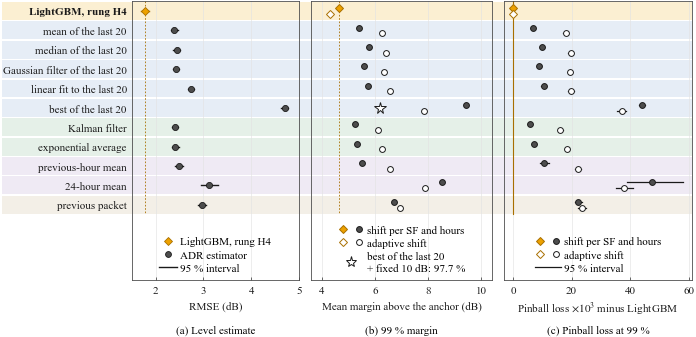

In [9]:
# Figure: the estimators against LightGBM on rung H4, hold-out, 99 % target; the rows grouped by kind of estimator and shaded, the shading running
# behind the labels and the three panels; the star marks the standard rule of the cell above; each panel carries its legend in white rows below
import paper_figures as pf
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import Rectangle
pf.use()
by_group = result[result.calibration == "SF x hours"].set_index("estimator")
by_aci = result[result.calibration == "ACI"].set_index("estimator")
lightgbm, kalman, average = "LightGBM on rung H4", f"Kalman filter, drift {q_best}", f"exponential average, weight {alpha}"
GROUPS = [("#fbefd2", [lightgbm]),
          ("#e6edf6", ["mean of the last 20", "median of the last 20", "Gaussian filter of the last 20", "linear regression over the last 20", "best of the last 20"]),
          ("#e5f0e8", [kalman, average]),
          ("#efeaf4", ["previous hour mean", "24 hour mean"]),
          ("#f3efe7", ["previous packet"])]
LABEL = {lightgbm: "LightGBM, rung H4", "linear regression over the last 20": "linear fit to the last 20", kalman: "Kalman filter", average: "exponential average",
         "previous hour mean": "previous-hour mean", "24 hour mean": "24-hour mean"}
rows = [name for _, names in GROUPS for name in names]
tint = {name: colour for colour, names in GROUPS for name in names}
assert sorted(rows) == sorted(est)                                               # every estimator, once
assert 1.5 < by_group.rmse_lo.min() and by_group.rmse_hi.max() < 5.0 and 3.6 < min(result.margin.min(), rule.mean())    # nothing outside the axes below
assert max(result.margin.max(), rule.mean()) < 10.4 and -3 < result.lo.min() and result.hi.max() < 61
fig = plt.figure(figsize=(pf.PAGE, 3.3))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.08, 1.12], wspace=0.07, left=0.19, right=0.993, top=0.985, bottom=0.14)
a = fig.add_subplot(gs[0, 0])
b = fig.add_subplot(gs[0, 1], sharey=a)
c = fig.add_subplot(gs[0, 2], sharey=a)
for ax in (a, b, c):
    ax.set_facecolor("none")                                                     # the row shading lies behind the axes
    ax.grid(axis="y", visible=False)
for i, name in enumerate(rows):
    fill, edge, marker = (pf.AMBER, pf.AMBER_DARK, "D") if name == lightgbm else (pf.INK2, pf.INK, "o")
    r = by_group.loc[name]
    a.plot([r.rmse_lo, r.rmse_hi], [i, i], color=edge, lw=1.0, zorder=2)
    a.plot(r.rmse, i, marker=marker, ms=4.4, mfc=fill, mec=edge, mew=0.6, ls="none", zorder=3)
    for frame, face, dy in ((by_group, fill, -0.15), (by_aci, "white", 0.15)):
        q = frame.loc[name]
        b.plot(q.margin, i + dy, marker=marker, ms=4.2, mfc=face, mec=edge, mew=0.7, ls="none", zorder=3)
        if name != lightgbm:
            c.plot([q.lo, q.hi], [i + dy, i + dy], color=edge, lw=0.9, zorder=2)
        c.plot(q.pinball_minus_lightgbm, i + dy, marker=marker, ms=4.2, mfc=face, mec=edge, mew=0.7, ls="none", zorder=3)
b.plot(rule.mean(), rows.index("best of the last 20"), marker="*", ms=8.5, mfc="white", mec=pf.INK, mew=0.7, ls="none", zorder=4)
a.set_yticks(range(len(rows)))
a.set_yticklabels([LABEL.get(name, name) for name in rows])
a.get_yticklabels()[0].set_fontweight("bold")
a.tick_params(axis="y", length=0)
b.tick_params(axis="y", length=0, labelleft=False)
c.tick_params(axis="y", length=0, labelleft=False)
a.set_ylim(len(rows) + 2.9, -0.5)                                                # empty rows at the bottom for the legends
a.set_xlim(1.5, 5.0)
a.set_xlabel("RMSE (dB)")
b.set_xlim(3.6, 10.4)
b.set_xlabel("Mean margin above the anchor (dB)")
c.set_xlim(-3, 61)
c.set_xlabel("Pinball loss $\\times 10^3$ minus LightGBM")
span = [-0.5, len(rows) - 0.5]                                                      # the reference lines run over the estimator rows only
a.plot([by_group.loc[lightgbm].rmse] * 2, span, color=pf.AMBER_DARK, lw=0.6, ls=(0, (2, 2)), zorder=1)
b.plot([by_group.loc[lightgbm].margin] * 2, span, color=pf.AMBER_DARK, lw=0.6, ls=(0, (2, 2)), zorder=1)
c.plot([0, 0], span, color=pf.AMBER_DARK, lw=0.8, zorder=1)
legend = dict(loc="lower center", borderaxespad=0.25, labelspacing=0.28, handletextpad=0.3, handlelength=1.6)
a.legend(handles=[Line2D([], [], marker="D", ls="none", ms=4.2, mfc=pf.AMBER, mec=pf.AMBER_DARK, mew=0.6, label="LightGBM, rung H4"),
                  Line2D([], [], marker="o", ls="none", ms=4.2, mfc=pf.INK2, mec=pf.INK, mew=0.6, label="ADR estimator"),
                  Line2D([], [], color=pf.INK, lw=1.0, label="95 % interval")], **legend)
def pair(face_lightgbm, face_estimator):                                         # the fill keys the calibration, for LightGBM and the estimators alike
    return (Line2D([], [], marker="D", ls="none", ms=4.2, mfc=face_lightgbm, mec=pf.AMBER_DARK, mew=0.7),
            Line2D([], [], marker="o", ls="none", ms=4.2, mfc=face_estimator, mec=pf.INK, mew=0.7))
calibration, names = [pair(pf.AMBER, pf.INK2), pair("white", "white")], ["shift per SF and hours", "adaptive shift"]
paired = dict(legend, handlelength=2.3, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)})
b.legend(handles=calibration + [Line2D([], [], marker="*", ls="none", ms=8, mfc="white", mec=pf.INK, mew=0.7)],
         labels=names + [f"best of the last 20\n+ fixed {fixed:.0f} dB: {100 * rule_coverage:.1f} %"], **paired)
c.legend(handles=calibration + [Line2D([], [], color=pf.INK, lw=0.9)], labels=names + ["95 % interval"], **paired)
pf.subcaptions(fig, [a, b, c], ["(a) Level estimate", "(b) 99 % margin", "(c) Pinball loss at 99 %"])
fig.canvas.draw()
to_fig = fig.transFigure.inverted()
for i, name in enumerate(rows):                                                  # the row shading, from the left edge of the labels to the right edge of (c)
    y0, y1 = (to_fig.transform(a.transData.transform((0, i + s)))[1] for s in (0.46, -0.46))
    fig.patches.append(Rectangle((0.004, y0), c.get_position().x1 - 0.004, y1 - y0, transform=fig.transFigure, facecolor=tint[name], edgecolor="none", zorder=-10))
fig.savefig("Figures/adr_estimators.png")
plt.show()

Reading of the results.

* LightGBM on rung H4 against the estimators of the adaptive data rate literature: on the hold-out the mean of the last 20 packets, the Kalman filter, the exponential average and the Gaussian filter reach 2.39, 2.40, 2.41 and 2.42 dB, close to the previous-hour mean (2.48 dB); LightGBM on rung H4 reaches 1.77 dB. In pinball loss the Kalman filter, the classical estimator closest to LightGBM, is 5.6 per thousand above it, with a 95 % interval from 5.1 to 6.2, the exponential average 7.1 (6.4 to 7.9) and the Gaussian filter 8.7 (8.1 to 9.6).
* The mean of the last 20 packets and the three filters lie within 0.03 dB of each other, so the filtering is not where LightGBM gains. It gains from what the classical estimators do not combine: windows of several lengths and the quantiles of the link's history in rung H1, and the same-channel history and the spreading factor in rung H4.
* The standard rule is the weakest estimator. The best of the last 20 packets selects the extreme and estimates the level with a 4.70 dB RMSE. A fixed 10 dB above it covers 97.7 % at a 99 % target, at a mean margin of 6.19 dB above the anchor. The same 10 dB above the mean of the last 20 packets covers 99.9 %.
* Calibration. A shift per group of spreading factor and working hours has a lower pinball loss than adaptive conformal inference with pooled scores for every estimator except the two weakest, the 24-hour mean and the best of the last 20 packets. The adaptive calibration holds every estimator at 99.0 to 99.1 % and cuts the clustering of the misses by 48 to 82 % for the classical estimators and by 18 % for LightGBM.
* The spreading factor shifts the measured path loss. Relative to the previous-hour mean, SF9 packets read 1.8 to 2.3 dB higher on every link and SF10 and SF11 packets 0.8 to 1.8 dB lower, while SF7 and SF8 stay within 0.52 dB and SF12 reads 0.5 to 0.8 dB higher. A translation of these path-loss estimators into an SNR rule has to account for these offsets.